# **Part A. Data Inspection and Potential Leakage**

In [38]:
import pandas as pd
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
df = pd.read_csv("/content/hybrid_student_performance_1200.csv")

df.head()

,student_id,timestamp,year_class,program_stream,age,gender,cgpa_category,academic_satisfaction,study_hours_daily,daily_productivity,...,projects_internships,programming_foundation,events_participation,assignments_on_time,attendance_percentage,strongest_asset,internal_barrier,external_resources,external_pressure,performance_risk_level
0,STU0001,3/29/2026 20:54:43,Second Year (SY),BCA,20,Female,8.5 – 9.4,Neutral,Less than 1 hour,2.0,...,"Yes, actively working on projects/internship","Basic knowledge, learning while practicing",Occasionally participate in events,Often,Above 85%,"Technical/Hard Skills (Coding, Math, Logic)",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),No Impact (Fully supportive environment),Moderate Risk
1,STU0002,3/29/2026 21:20:15,Second Year (SY),BCA,20,Male,8.5 – 9.4,Unsatisfied,1–2 hours,1.0,...,"Yes, actively working on projects/internship","Limited knowledge, theoretical only","Rarely participate, mostly observe",Often,76% – 85%,"Creative/Design Skills (Innovation, UI/UX, Con...",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),Moderate Impact (Occasional disruption),Moderate Risk
2,STU0003,3/29/2026 21:21:35,Second Year (SY),BCA,19,Male,5.0 – 6.9,Neutral,1–2 hours,2.0,...,"Yes, actively working on projects/internship","Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,Less than 50%,"Technical/Hard Skills (Coding, Math, Logic)",Difficulty with Focus / Concentration,Rarely (Passive),High Impact (Frequent disruption),High Risk
3,STU0004,3/29/2026 21:27:44,Second Year (SY),BCA,19,Female,8.5 – 9.4,Satisfied,1–2 hours,3.0,...,Planning to start a project/internship soon,"Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,Above 85%,"Management/Execution (Planning, Organizing, Di...",Procrastination / Low Motivation,Occasionally (When needed),High Impact (Frequent disruption),Low Risk
4,STU0005,3/29/2026 22:05:14,Second Year (SY),BCA,20,Female,8.5 – 9.4,Neutral,1–2 hours,2.0,...,Planning to start a project/internship soon,"Basic knowledge, learning while practicing",Occasionally participate in events,Often,76% – 85%,"Management/Execution (Planning, Organizing, Di...",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),High Impact (Frequent disruption),High Risk


In [40]:
df.columns

Index(['student_id', 'timestamp', 'year_class', 'program_stream', 'age',
       'gender', 'cgpa_category', 'academic_satisfaction', 'study_hours_daily',
       'daily_productivity', 'revision_frequency', 'focus_duration',
       'screen_time_non_study', 'main_distractor', 'study_consistency',
       'tasks_on_time', 'preparation_status', 'career_goal_clarity',
       'skills_developing', 'energy_level', 'stress_level', 'routine_rating',
       'sleepy_during_study', 'sleep_hours', 'career_interest',
       'online_courses', 'projects_internships', 'programming_foundation',
       'events_participation', 'assignments_on_time', 'attendance_percentage',
       'strongest_asset', 'internal_barrier', 'external_resources',
       'external_pressure', 'performance_risk_level'],
      dtype='object')

In [41]:
df.shape

(1200, 36)

In [42]:
def extract_range_mean(val):
    if pd.isna(val):
        return np.nan
    parts = str(val).replace("–", "-").split("-")
    if len(parts) == 2:
        return (float(parts[0]) + float(parts[1])) / 2.0
    return np.nan

df["final_cgpa"] = df['cgpa_category'].apply(extract_range_mean)
df["final_cgpa"]


,final_cgpa
0,8.95
1,8.95
2,5.95
3,8.95
4,8.95
...,...
1195,8.95
1196,9.75
1197,7.70
1198,8.95


In [43]:
selected_cols = [
    "student_id",
    "timestamp",
    "final_cgpa",
    "performance_risk_level",
    "study_hours_daily",
    "sleep_hours",
    "attendance_percentage",
    "study_consistency",
    "tasks_on_time",
    "assignments_on_time",
    "revision_frequency",
    "career_goal_clarity",
    "daily_productivity",
    "stress_level",
    "age",
]
data = df[selected_cols].copy()
data

,student_id,timestamp,final_cgpa,performance_risk_level,study_hours_daily,sleep_hours,attendance_percentage,study_consistency,tasks_on_time,assignments_on_time,revision_frequency,career_goal_clarity,daily_productivity,stress_level,age
0,STU0001,3/29/2026 20:54:43,8.95,Moderate Risk,Less than 1 hour,6–7 hours,Above 85%,Rarely,Sometimes,Often,Never,Somewhat clear,2.0,4.0,20
1,STU0002,3/29/2026 21:20:15,8.95,Moderate Risk,1–2 hours,6–7 hours,76% – 85%,Sometimes,Sometimes,Often,Rarely,Somewhat clear,1.0,3.0,20
2,STU0003,3/29/2026 21:21:35,5.95,High Risk,1–2 hours,6–7 hours,Less than 50%,Mostly consistent,Often,Often,Few times a week,Very clear,2.0,5.0,19
3,STU0004,3/29/2026 21:27:44,8.95,Low Risk,1–2 hours,6–7 hours,Above 85%,Sometimes,Often,Often,Rarely,Somewhat clear,3.0,2.0,19
4,STU0005,3/29/2026 22:05:14,8.95,High Risk,1–2 hours,4–5 hours,76% – 85%,Sometimes,Sometimes,Often,Rarely,Somewhat clear,2.0,5.0,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,STU1196,03/23/2026 10:57:00,8.95,Moderate Risk,1–2 hours,6–7 hours,76% – 85%,Rarely,Sometimes,Often,Few times a week,Very clear,4.0,2.0,19
1196,STU1197,03/19/2026 07:38:00,9.75,Moderate Risk,1–2 hours,NaN,76% – 85%,Sometimes,Sometimes,Sometimes,Rarely,Very clear,3.0,4.0,18
1197,STU1198,03/23/2026 14:07:00,7.70,High Risk,1–2 hours,6–7 hours,50% – 65%,Sometimes,Always,Often,Few times a week,Somewhat clear,3.0,5.0,17
1198,STU1199,03/21/2026 06:19:00,8.95,High Risk,Less than 1 hour,6–7 hours,50% – 65%,Sometimes,Rarely,Always,Rarely,Very clear,2.0,4.0,21


In [44]:
ordinal_mappings = {
    "performance_risk_level": {"Low Risk": 0, "Moderate Risk": 1, "High Risk": 2},
    "revision_frequency": {"Never": 0, "Rarely": 1, "Few times a week": 2, "Daily": 3},
    "study_hours_daily": {"Less than 1 hour": 0, "1–2 hours": 1, "More than 2 hours": 2},
    "career_goal_clarity": {"Not clear": 0, "Somewhat clear": 1, "Very clear": 2},
    "study_consistency": {"Rarely": 0, "Sometimes": 1, "Mostly consistent": 2},
    "sleep_hours": {"4–5 hours": 0, "6–7 hours": 1, "More than 8 hours": 2},
    "attendance_percentage": {"Less than 50%": 0, "50% – 65%": 1, "66% – 75%": 2, "76% – 85%": 3, "Above 85%": 4},
    "tasks_on_time": {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3},
    "assignments_on_time": {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3},
}

for col, mapping in ordinal_mappings.items():
  if col in data.columns:
    data[f"{col}_encoded"] = data[col].map(mapping)

In [45]:
if "program_stream" in df.columns and "year_class" in df.columns:
    data["cohort_code"] = (
        df["program_stream"].astype(str) + " | " + df["year_class"].astype(str)
    )
data["effort_index"] = (
    data["study_hours_daily_encoded"] * (data["attendance_percentage_encoded"] / 100)
)

In [46]:
data.columns

Index(['student_id', 'timestamp', 'final_cgpa', 'performance_risk_level',
       'study_hours_daily', 'sleep_hours', 'attendance_percentage',
       'study_consistency', 'tasks_on_time', 'assignments_on_time',
       'revision_frequency', 'career_goal_clarity', 'daily_productivity',
       'stress_level', 'age', 'performance_risk_level_encoded',
       'revision_frequency_encoded', 'study_hours_daily_encoded',
       'career_goal_clarity_encoded', 'study_consistency_encoded',
       'sleep_hours_encoded', 'attendance_percentage_encoded',
       'tasks_on_time_encoded', 'assignments_on_time_encoded', 'cohort_code',
       'effort_index'],
      dtype='object')

In [47]:
data.shape

(1200, 26)

<Axes: >

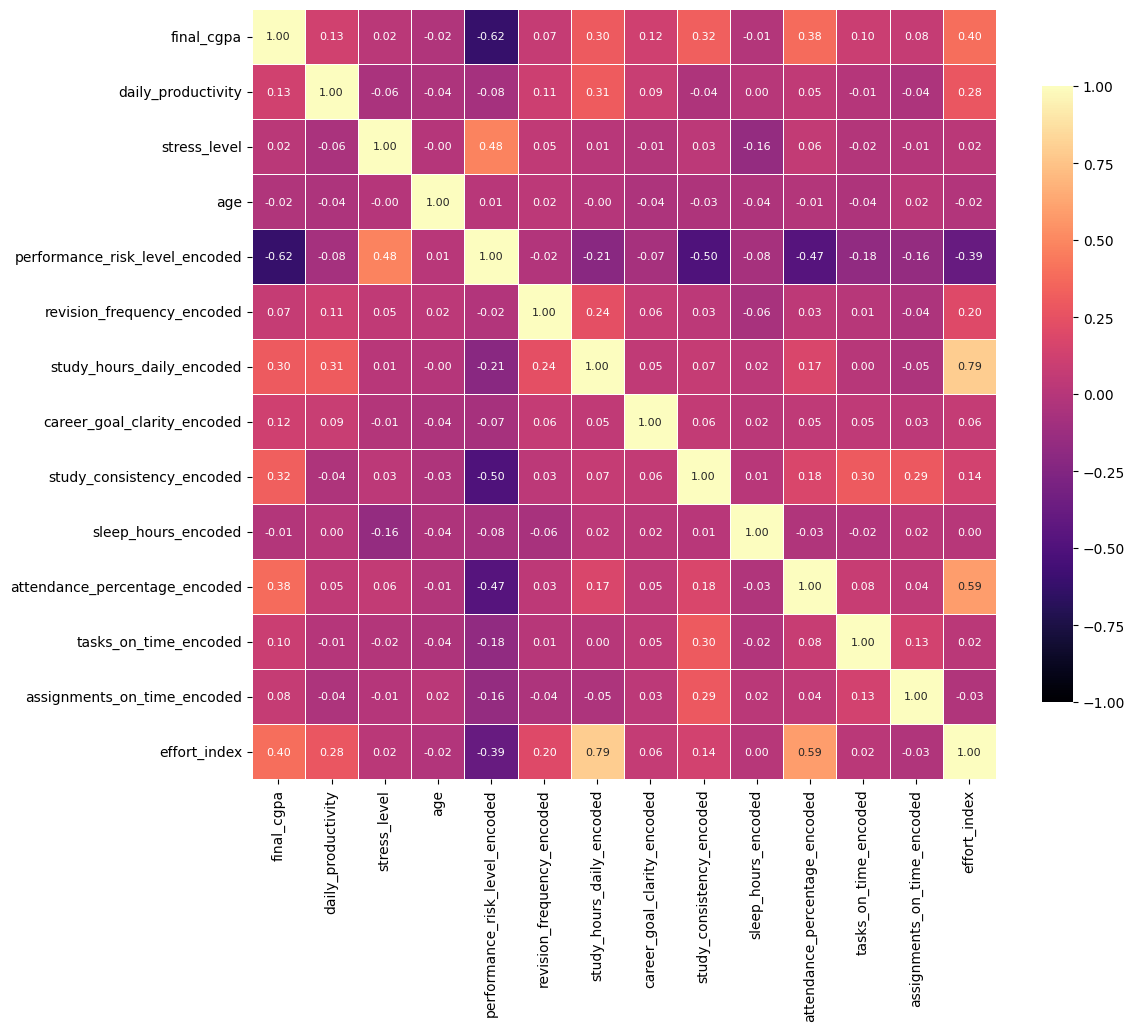

In [48]:
tocorr = data.select_dtypes(include=[np.number])
corr = tocorr.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    cmap="magma",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 8},
)

In [49]:
data['timestamp'] = pd.to_datetime(data['timestamp'], errors='coerce')

In [50]:
data = data.sort_values(by="timestamp").reset_index(drop=True)
data.head()

,student_id,timestamp,final_cgpa,performance_risk_level,study_hours_daily,sleep_hours,attendance_percentage,study_consistency,tasks_on_time,assignments_on_time,...,revision_frequency_encoded,study_hours_daily_encoded,career_goal_clarity_encoded,study_consistency_encoded,sleep_hours_encoded,attendance_percentage_encoded,tasks_on_time_encoded,assignments_on_time_encoded,cohort_code,effort_index
0,STU0068,2026-03-15 01:07:00,7.70,High Risk,Less than 1 hour,6–7 hours,76% – 85%,Rarely,Sometimes,Always,...,3.0,0,2,0,1.0,3,1,3,BSc IT | Second Year (SY),0.00
1,STU0343,2026-03-15 06:48:00,7.70,High Risk,More than 2 hours,6–7 hours,Less than 50%,Rarely,Sometimes,Always,...,2.0,2,1,0,1.0,0,1,3,BCA | Second Year (PG),0.00
2,STU0194,2026-03-15 07:56:00,7.70,High Risk,Less than 1 hour,More than 8 hours,50% – 65%,Mostly consistent,Often,Often,...,2.0,0,1,2,2.0,1,2,2,BCA | Third Year (TY),0.00
3,STU0149,2026-03-15 08:53:00,8.95,Moderate Risk,1–2 hours,6–7 hours,Above 85%,Mostly consistent,Often,Sometimes,...,0.0,1,0,2,1.0,4,2,1,BBA | First Year (FY),0.04
4,STU1126,2026-03-15 09:03:00,7.70,High Risk,Less than 1 hour,More than 8 hours,50% – 65%,Rarely,Always,Often,...,2.0,0,1,0,2.0,1,3,2,BSc IT | Final Year,0.00


In [51]:
data_nu = data.select_dtypes(include=[np.number])
data_nu

,final_cgpa,daily_productivity,stress_level,age,performance_risk_level_encoded,revision_frequency_encoded,study_hours_daily_encoded,career_goal_clarity_encoded,study_consistency_encoded,sleep_hours_encoded,attendance_percentage_encoded,tasks_on_time_encoded,assignments_on_time_encoded,effort_index
0,7.70,1.0,4.0,21,2,3.0,0,2,0,1.0,3,1,3,0.00
1,7.70,4.0,4.0,25,2,2.0,2,1,0,1.0,0,1,3,0.00
2,7.70,4.0,4.0,21,2,2.0,0,1,2,2.0,1,2,2,0.00
3,8.95,2.0,5.0,17,1,0.0,1,0,2,1.0,4,2,1,0.04
4,7.70,NaN,3.0,23,2,2.0,0,1,0,2.0,1,3,2,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,7.70,2.0,2.0,21,2,1.0,2,1,0,1.0,1,1,1,0.02
1196,5.95,3.0,4.0,21,2,2.0,2,0,0,1.0,2,2,3,0.04
1197,5.95,2.0,4.0,25,2,1.0,0,2,0,1.0,0,1,1,0.00
1198,8.95,5.0,3.0,17,0,0.0,2,0,2,1.0,4,3,1,0.08


In [52]:
data_nu.isna().sum()

,0
final_cgpa,0
daily_productivity,34
stress_level,35
age,0
performance_risk_level_encoded,0
revision_frequency_encoded,34
study_hours_daily_encoded,0
career_goal_clarity_encoded,0
study_consistency_encoded,0
sleep_hours_encoded,55


In [53]:
data_nu.duplicated().value_counts()

,count
False,1200


In [54]:
pd.crosstab(data['final_cgpa'], data['performance_risk_level'])

performance_risk_level,High Risk,Low Risk,Moderate Risk
final_cgpa,,,
5.95,188,0,48
7.70,221,4,195
8.95,39,89,234
9.75,4,83,95


In [55]:
min_cohort = data[data["cohort_code"].map(data["cohort_code"].value_counts()) < 10]
min_cohort["cohort_code"].value_counts()

,count
cohort_code,
BCom | Second Year (PG),9
BA | First Year (PG),8
BSc Cyber Security | Second Year (PG),7
BA | First Year (FY),7
BCom | Final Year,6
BBA | First Year (PG),6
BBA | Final Year,6
BA | Second Year (PG),6
BSc IT | Second Year (PG),5


<Axes: xlabel='timestamp', ylabel='final_cgpa'>

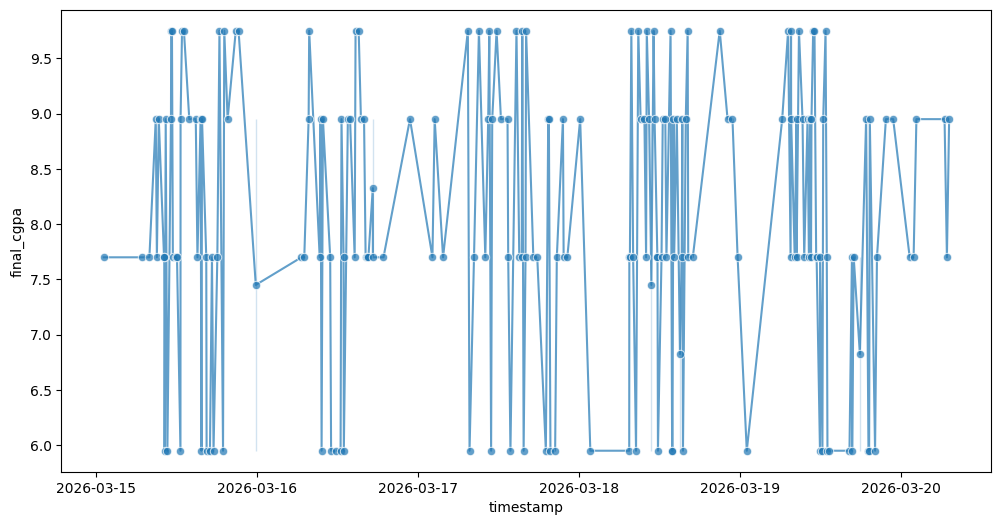

In [56]:
sample = data.head(200)
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=sample, x="timestamp", y="final_cgpa", marker="o", alpha=0.7
)

# Key Risks of Data Leakage & Overfitting:
- **Target Leakage via performance_risk_level:** Using features like performance risk status alongside target variables can cause severe target leakage if that risk level is evaluated using end-of-term outcomes, leading to unrealistically high validation accuracy that fails in production.

- **Feature Redundancy from effort_index:** Because effort_index is directly calculated from study_hours_daily and attendance_percentage, keeping both raw features and the derived index introduces high multicollinearity, causing model overfitting and unstable coefficient weights in linear models.

- **Temporal Data Leakage:** Randomly splitting data without respecting the timestamp ordering can lead to train-test contamination, where models inadvertently learn patterns from future survey responses to predict past instances.

- **Bin Approximation Overfitting:** Converting range-based cgpa_category values into fixed midpoints (final_cgpa) creates artificial clustering or plateaus. Machine learning models may overfit to these discrete steps instead of learning genuine continuous variance.

# **Part B. Impact of Data Leakage and Evaluation Strategy**

In [57]:
data_nu.columns

Index(['final_cgpa', 'daily_productivity', 'stress_level', 'age',
       'performance_risk_level_encoded', 'revision_frequency_encoded',
       'study_hours_daily_encoded', 'career_goal_clarity_encoded',
       'study_consistency_encoded', 'sleep_hours_encoded',
       'attendance_percentage_encoded', 'tasks_on_time_encoded',
       'assignments_on_time_encoded', 'effort_index'],
      dtype='object')

In [58]:
data_nu = data_nu.drop(columns=['performance_risk_level_encoded'])
data_nu

,final_cgpa,daily_productivity,stress_level,age,revision_frequency_encoded,study_hours_daily_encoded,career_goal_clarity_encoded,study_consistency_encoded,sleep_hours_encoded,attendance_percentage_encoded,tasks_on_time_encoded,assignments_on_time_encoded,effort_index
0,7.70,1.0,4.0,21,3.0,0,2,0,1.0,3,1,3,0.00
1,7.70,4.0,4.0,25,2.0,2,1,0,1.0,0,1,3,0.00
2,7.70,4.0,4.0,21,2.0,0,1,2,2.0,1,2,2,0.00
3,8.95,2.0,5.0,17,0.0,1,0,2,1.0,4,2,1,0.04
4,7.70,NaN,3.0,23,2.0,0,1,0,2.0,1,3,2,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,7.70,2.0,2.0,21,1.0,2,1,0,1.0,1,1,1,0.02
1196,5.95,3.0,4.0,21,2.0,2,0,0,1.0,2,2,3,0.04
1197,5.95,2.0,4.0,25,1.0,0,2,0,1.0,0,1,1,0.00
1198,8.95,5.0,3.0,17,0.0,2,0,2,1.0,4,3,1,0.08


In [143]:
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder, TargetEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor

In [77]:
y = data_nu['final_cgpa']
X = data_nu.drop(columns=['final_cgpa'])

## Random split::

In [78]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y, test_size=0.2, random_state=42)

In [79]:
X.columns

Index(['daily_productivity', 'stress_level', 'age',
       'revision_frequency_encoded', 'study_hours_daily_encoded',
       'career_goal_clarity_encoded', 'study_consistency_encoded',
       'sleep_hours_encoded', 'attendance_percentage_encoded',
       'tasks_on_time_encoded', 'assignments_on_time_encoded', 'effort_index'],
      dtype='object')

In [80]:
baseline_pred_r = np.full_like(y_test_r, y_train_r.mean())
baseline_rmse_r = np.sqrt(mean_squared_error(y_test_r, baseline_pred_r))
baseline_mae_r = mean_absolute_error(y_test_r, baseline_pred_r)
baseline_r2_r = r2_score(y_test_r, baseline_pred_r)

In [84]:
ml_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", DecisionTreeRegressor(criterion="squared_error", random_state=42)),
    ]
)

In [85]:
ml_pipeline.fit(X_train_r, y_train_r)

train_rmse_r = np.sqrt(
    mean_squared_error(y_train_r, ml_pipeline.predict(X_train_r))
)
test_rmse_r = np.sqrt(mean_squared_error(y_test_r, ml_pipeline.predict(X_test_r)))

print("--- RANDOM SPLIT (80/20) ---")
print(f"Baseline RMSE: {baseline_rmse_r:.4f}")
print(f"Training RMSE: {train_rmse_r:.4f}")
print(f"Testing RMSE:  {test_rmse_r:.4f}\n")

--- RANDOM SPLIT (80/20) ---
Baseline RMSE: 1.3385
Training RMSE: 0.0399
Testing RMSE:  1.6232



## Chronological split::

In [86]:
split_idx = int(len(X) * 0.8)

X_train_c, X_test_c = X.iloc[:split_idx], X.iloc[split_idx:]
y_train_c, y_test_c = y.iloc[:split_idx], y.iloc[split_idx:]

In [87]:
baseline_pred_c = np.full_like(y_test_c, y_train_c.mean())
baseline_rmse_c = np.sqrt(mean_squared_error(y_test_c, baseline_pred_c))

In [88]:
ml_pipeline.fit(X_train_c, y_train_c)

train_rmse_c = np.sqrt(
    mean_squared_error(y_train_c, ml_pipeline.predict(X_train_c))
)
test_rmse_c = np.sqrt(mean_squared_error(y_test_c, ml_pipeline.predict(X_test_c)))

In [89]:
print("--- CHRONOLOGICAL SPLIT (80/20) ---")
print(f"Baseline RMSE: {baseline_rmse_c:.4f}")
print(f"Training RMSE: {train_rmse_c:.4f}")
print(f"Testing RMSE:  {test_rmse_c:.4f}")

--- CHRONOLOGICAL SPLIT (80/20) ---
Baseline RMSE: 1.2362
Training RMSE: 0.0399
Testing RMSE:  1.5761


In [90]:
results_data = {
    "Split Strategy": ["Random Split (80/20)", "Chronological Split (80/20)"],
    "Baseline RMSE": [baseline_rmse_r, baseline_rmse_c],
    "Training RMSE": [train_rmse_r, train_rmse_c],
    "Testing RMSE": [test_rmse_r, test_rmse_c],
}

results_df = pd.DataFrame(results_data)
results_df.round(3)

,Split Strategy,Baseline RMSE,Training RMSE,Testing RMSE
0,Random Split (80/20),1.338,0.04,1.623
1,Chronological Split (80/20),1.236,0.04,1.576


In [91]:
data_d = data.copy()
n_duplicates = int(len(data_d) * 0.15)
duplicate_indices = np.random.choice(
    data_d.index, size=n_duplicates, replace=True
)
df_dup = data_d.loc[duplicate_indices].copy()
df_dup

,student_id,timestamp,final_cgpa,performance_risk_level,study_hours_daily,sleep_hours,attendance_percentage,study_consistency,tasks_on_time,assignments_on_time,...,revision_frequency_encoded,study_hours_daily_encoded,career_goal_clarity_encoded,study_consistency_encoded,sleep_hours_encoded,attendance_percentage_encoded,tasks_on_time_encoded,assignments_on_time_encoded,cohort_code,effort_index
592,STU0008,2026-03-30 07:11:40,5.95,High Risk,1–2 hours,6–7 hours,50% – 65%,Mostly consistent,Often,Often,...,2.0,1,1,2,1.0,1,2,2,BCA | Second Year (SY),0.01
565,STU1031,2026-03-29 14:41:00,8.95,Moderate Risk,1–2 hours,4–5 hours,66% – 75%,Sometimes,Sometimes,Often,...,0.0,1,1,1,0.0,2,1,2,BSc Cyber Security | Third Year (TY),0.02
191,STU0373,2026-03-19 20:27:00,7.70,High Risk,Less than 1 hour,6–7 hours,50% – 65%,Sometimes,Often,Rarely,...,1.0,0,1,1,1.0,1,2,0,BCA | First Year (FY),0.00
400,STU0646,2026-03-24 20:09:00,8.95,Moderate Risk,More than 2 hours,NaN,76% – 85%,Mostly consistent,Always,Often,...,2.0,2,1,2,NaN,3,3,2,BCom | First Year (FY),0.06
49,STU0274,2026-03-16 10:54:00,7.70,High Risk,More than 2 hours,More than 8 hours,50% – 65%,Rarely,Sometimes,Sometimes,...,2.0,2,2,0,2.0,1,1,1,BSc Cyber Security | Third Year (TY),0.02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
389,STU0533,2026-03-24 15:13:00,9.75,Moderate Risk,1–2 hours,6–7 hours,66% – 75%,Sometimes,Rarely,Sometimes,...,0.0,1,2,1,1.0,2,0,1,BCA | Second Year (PG),0.02
799,STU0152,2026-04-04 08:11:00,9.75,Moderate Risk,More than 2 hours,6–7 hours,Less than 50%,Sometimes,Rarely,Often,...,2.0,2,1,1,1.0,0,0,2,BCom | First Year (FY),0.00
553,STU0135,2026-03-29 11:11:00,7.70,Moderate Risk,1–2 hours,6–7 hours,Above 85%,Sometimes,Always,Often,...,2.0,1,1,1,1.0,4,3,2,BCA | First Year (FY),0.04
1051,STU0153,2026-04-11 01:19:00,8.95,Moderate Risk,1–2 hours,4–5 hours,76% – 85%,Rarely,Rarely,Always,...,3.0,1,1,0,0.0,3,0,3,BCom | First Year (FY),0.03


In [92]:
min_time = data_d["timestamp"].min()
max_time = data_d["timestamp"].max()
time_range_seconds = (max_time - min_time).total_seconds()
random_seconds = np.random.uniform(0, time_range_seconds, size=len(df_dup))
df_dup["timestamp"] = min_time + pd.to_timedelta(random_seconds, unit="s")

df_augmented = (
    pd.concat([data_d, df_dup], ignore_index=True)
    .sort_values("timestamp")
    .reset_index(drop=True)
)

In [93]:
feature_cols = ['daily_productivity', 'stress_level', 'age',
       'revision_frequency_encoded', 'study_hours_daily_encoded',
       'career_goal_clarity_encoded', 'study_consistency_encoded',
       'sleep_hours_encoded', 'attendance_percentage_encoded',
       'tasks_on_time_encoded', 'assignments_on_time_encoded', 'effort_index']
target_col = 'final_cgpa'

In [94]:
def evaluate_model(train_df, test_df):
  X_train = train_df[feature_cols]
  y_train = train_df[target_col]
  X_test = test_df[feature_cols]
  y_test = test_df[target_col]

  baseline_pred = np.full_like(y_test, y_train.mean())
  baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

  # Train Decision Tree
  dt = DecisionTreeRegressor(random_state=42)
  dt.fit(X_train, y_train)

  train_rmse = np.sqrt(mean_squared_error(y_train, dt.predict(X_train)))
  test_rmse = np.sqrt(mean_squared_error(y_test, dt.predict(X_test)))

  return baseline_rmse, train_rmse, test_rmse

### Splitting before removing duplicates

In [95]:
split_idx_1 = int(len(df_augmented) * 0.8)
train_1 = df_augmented.iloc[:split_idx_1]
test_1 = df_augmented.iloc[split_idx_1:]

b_rmse_1, tr_rmse_1, te_rmse_1 = evaluate_model(train_1, test_1)

print("--- SPLITTING BEFORE REMOVING DUPLICATES ---")
print(f"Baseline RMSE: {b_rmse_1:.4f}")
print(f"Training RMSE: {tr_rmse_1:.4f}")
print(f"Testing RMSE:  {te_rmse_1:.4f}")

--- SPLITTING BEFORE REMOVING DUPLICATES ---
Baseline RMSE: 1.2575
Training RMSE: 0.1440
Testing RMSE:  1.3669


### Removing duplicates before splitting

In [97]:
cols_to_check = [c for c in df_augmented.columns if c != "timestamp"]
df_deduped = df_augmented.drop_duplicates(
    subset=cols_to_check, keep="first"
).reset_index(drop=True)

split_idx_2 = int(len(df_deduped) * 0.8)
train_2 = df_deduped.iloc[:split_idx_2]
test_2 = df_deduped.iloc[split_idx_2:]

b_rmse_2, tr_rmse_2, te_rmse_2 = evaluate_model(train_2, test_2)

print("--- REMOVING DUPLICATES BEFORE SPLITTING ---")
print(f"Baseline RMSE: {b_rmse_2:.4f}")
print(f"Training RMSE: {tr_rmse_2:.4f}")
print(f"Testing RMSE:  {te_rmse_2:.4f}")

--- REMOVING DUPLICATES BEFORE SPLITTING ---
Baseline RMSE: 1.2339
Training RMSE: 0.1168
Testing RMSE:  1.4993


In [98]:
results_data_dup = {
    "Split Strategy": ["REMOVING DUPLICATES BEFORE SPLITTING", "SPLITTING BEFORE REMOVING DUPLICATES"],
    "Baseline RMSE": [b_rmse_1, b_rmse_2],
    "Training RMSE": [tr_rmse_1, tr_rmse_2],
    "Testing RMSE": [te_rmse_1, te_rmse_2],
}

results_dup_df = pd.DataFrame(results_data_dup)
results_dup_df.round(3)

,Split Strategy,Baseline RMSE,Training RMSE,Testing RMSE
0,REMOVING DUPLICATES BEFORE SPLITTING,1.257,0.144,1.367
1,SPLITTING BEFORE REMOVING DUPLICATES,1.234,0.117,1.499


In [101]:
ml_pipeline_scal = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=10)),
    ]
)

ml_pipeline_no_scal = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", KNeighborsRegressor(n_neighbors=10)),
    ]
)

### Fit StandardScaler on ENTIRE dataset before splitting

In [104]:
scaler = StandardScaler()
X_scal = scaler.fit_transform(X)

X_train_scal, X_test_scal, y_train_scal, y_test_scal = train_test_split(
    X_scal, y, test_size=0.2, random_state=42
)

ml_pipeline_no_scal.fit(X_train_scal, y_train_scal)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model', KNeighborsRegressor(n_neighbors=10))])

In [106]:
train_rmse_s1 = np.sqrt(
    mean_squared_error(y_train_scal, ml_pipeline_no_scal.predict(X_train_scal))
)
test_rmse_s1 = np.sqrt(
    mean_squared_error(y_test_scal, ml_pipeline_no_scal.predict(X_test_scal))
)

print("--- Fit StandardScaler on ENTIRE dataset before splitting ---")
print(f"Training RMSE: {train_rmse_s1:.4f}")
print(f"Testing RMSE:  {test_rmse_s1:.4f}")

--- Fit StandardScaler on ENTIRE dataset before splitting ---
Training RMSE: 1.0157
Testing RMSE:  1.1841


### Fit StandardScaler on TRAINING data only

In [108]:
ml_pipeline_scal.fit(X_train_r, y_train_r)

train_rmse_s2 = np.sqrt(
    mean_squared_error(y_train_r, ml_pipeline_scal.predict(X_train_r))
)
test_rmse_s2 = np.sqrt(
    mean_squared_error(y_test_r, ml_pipeline_scal.predict(X_test_r))
)

print("--- Fit StandardScaler on TRAINING data only ---")
print(f"Training RMSE: {train_rmse_s2:.4f}")
print(f"Testing RMSE:  {test_rmse_s2:.4f}")

--- Fit StandardScaler on TRAINING data only ---
Training RMSE: 1.0192
Testing RMSE:  1.1886


In [109]:
results_data_scal = {
    "Fitting Strategy": ["StandardScaler on ENTIRE dataset", "StandardScaler on TRAINING data"],
    "Training RMSE": [train_rmse_s1, train_rmse_s2],
    "Testing RMSE": [test_rmse_s1, test_rmse_s2],
}

results_scal_df = pd.DataFrame(results_data_scal)
results_scal_df.round(3)

,Fitting Strategy,Training RMSE,Testing RMSE
0,StandardScaler on ENTIRE dataset,1.016,1.184
1,StandardScaler on TRAINING data,1.019,1.189


# **Part C. Understanding and Diagnosing Overfitting**

### chronological split with `max_depth` tuning

In [110]:
max_depth = [1, 2, 3, 5, 10, 20, None]
max_depth_tr_rmse_c = []
max_depth_te_rmse_c = []

for md in max_depth:
  ml_pipeline.fit(X_train_c, y_train_c)
  train_rmse = np.sqrt(mean_squared_error(y_train_c, ml_pipeline.predict(X_train_c)))
  test_rmse = np.sqrt(mean_squared_error(y_test_c, ml_pipeline.predict(X_test_c)))
  max_depth_tr_rmse_c.append(train_rmse)
  max_depth_te_rmse_c.append(test_rmse)
  print(f"Max Depth: {md} -- Training RMSE: {train_rmse:.4f} -- Testing RMSE: {test_rmse:.4f}")

Max Depth: 1 -- Training RMSE: 0.0399 -- Testing RMSE: 1.5761
Max Depth: 2 -- Training RMSE: 0.0399 -- Testing RMSE: 1.5761
Max Depth: 3 -- Training RMSE: 0.0399 -- Testing RMSE: 1.5761
Max Depth: 5 -- Training RMSE: 0.0399 -- Testing RMSE: 1.5761
Max Depth: 10 -- Training RMSE: 0.0399 -- Testing RMSE: 1.5761
Max Depth: 20 -- Training RMSE: 0.0399 -- Testing RMSE: 1.5761
Max Depth: None -- Training RMSE: 0.0399 -- Testing RMSE: 1.5761


In [114]:
max_depth_tr_rmse_r = []
max_depth_te_rmse_r = []

for md in max_depth:
  ml_pipeline.fit(X_train_r, y_train_r)
  train_rmse = np.sqrt(mean_squared_error(y_train_r, ml_pipeline.predict(X_train_r)))
  test_rmse = np.sqrt(mean_squared_error(y_test_r, ml_pipeline.predict(X_test_r)))
  max_depth_tr_rmse_r.append(train_rmse)
  max_depth_te_rmse_r.append(test_rmse)
  print(f"Max Depth: {md} -- Training RMSE: {train_rmse:.4f} -- Testing RMSE: {test_rmse:.4f}")

Max Depth: 1 -- Training RMSE: 0.0399 -- Testing RMSE: 1.6232
Max Depth: 2 -- Training RMSE: 0.0399 -- Testing RMSE: 1.6232
Max Depth: 3 -- Training RMSE: 0.0399 -- Testing RMSE: 1.6232
Max Depth: 5 -- Training RMSE: 0.0399 -- Testing RMSE: 1.6232
Max Depth: 10 -- Training RMSE: 0.0399 -- Testing RMSE: 1.6232
Max Depth: 20 -- Training RMSE: 0.0399 -- Testing RMSE: 1.6232
Max Depth: None -- Training RMSE: 0.0399 -- Testing RMSE: 1.6232


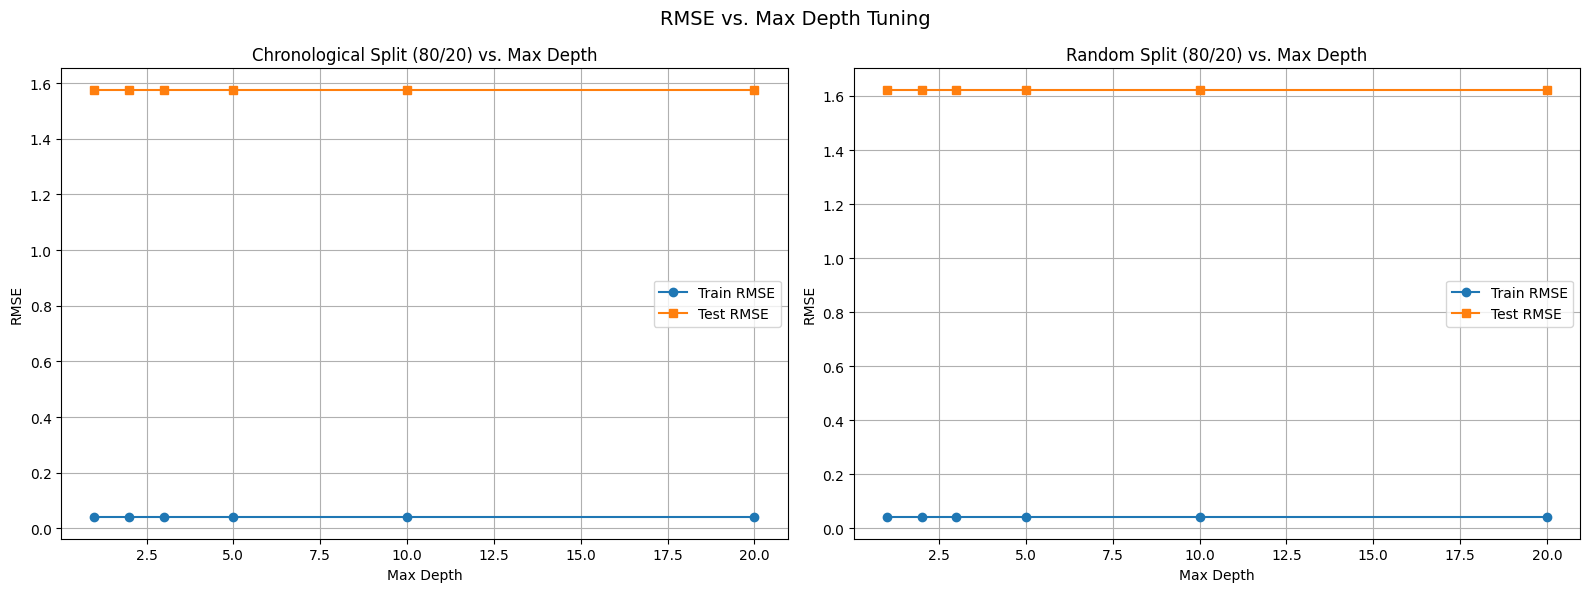

In [116]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

ax[0].plot(max_depth, max_depth_tr_rmse_c, label="Train RMSE", marker='o')
ax[0].plot(max_depth, max_depth_te_rmse_c, label="Test RMSE", marker='s')
ax[0].set_xlabel("Max Depth")
ax[0].set_ylabel("RMSE")
ax[0].set_title("Chronological Split (80/20) vs. Max Depth")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(max_depth, max_depth_tr_rmse_r, label="Train RMSE", marker='o')
ax[1].plot(max_depth, max_depth_te_rmse_r, label="Test RMSE", marker='s')
ax[1].set_xlabel("Max Depth")
ax[1].set_ylabel("RMSE")
ax[1].set_title("Random Split (80/20) vs. Max Depth")
ax[1].legend()
ax[1].grid(True)

plt.suptitle("RMSE vs. Max Depth Tuning", fontsize=14)
plt.tight_layout()
plt.show()

In [122]:
gen_gap_c = np.array(max_depth_te_rmse_c) - np.array(max_depth_tr_rmse_c)
gen_gap_r = np.array(max_depth_te_rmse_r) - np.array(max_depth_tr_rmse_r)

print("Generalization Gap (Chronological Split):", gen_gap_c.round(3))
print("Generalization Gap (Random Split):", gen_gap_r.round(3))

Generalization Gap (Chronological Split): [1.536 1.536 1.536 1.536 1.536 1.536 1.536]
Generalization Gap (Random Split): [1.583 1.583 1.583 1.583 1.583 1.583 1.583]


In [127]:
X_train_c = X_train_c[["effort_index"]]

degrees = [1, 2, 3, 5, 9, 15]
tscv = TimeSeriesSplit(n_splits=5)
cv_rmse_results = []

for deg in degrees:
  fold_rmses = []

  for train_idx, val_idx in tscv.split(X_train_c):
    X_tr, X_val = X_train_c.iloc[train_idx], X_train_c.iloc[val_idx]
    y_tr, y_val = y_train_c.iloc[train_idx], y_train_c.iloc[val_idx]

    pipe = Pipeline([
        ("poly", PolynomialFeatures(degree=deg, include_bias=False)),
        ("scaler", StandardScaler()),
        ("reg", LinearRegression()),
    ])

    pipe.fit(X_tr, y_tr)
    preds = pipe.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    fold_rmses.append(rmse)

  cv_rmse_results.append(np.mean(fold_rmses))

cv_results_df = pd.DataFrame(
    {"Polynomial Degree": degrees, "Cross-Validation RMSE": cv_rmse_results}
)

cv_results_df.round(3)

,Polynomial Degree,Cross-Validation RMSE
0,1,1.167
1,2,1.166
2,3,1.166
3,5,1.167
4,9,1.166
5,15,1.166


# **Part D. Improving Model Generalization**

In [135]:
numeric_features = [
    "study_hours_daily_encoded",
    "sleep_hours_encoded",
    "attendance_percentage_encoded",
    "daily_productivity",
    "stress_level",
    "age",
    "effort_index",
]

In [139]:
split_idx = int(len(data) * 0.8)

all_features = [col for col in data.columns if col in numeric_features or col == "cohort_code"]
X_full = data[all_features]
y_full = data["final_cgpa"]

X_train_c = X_full.iloc[:split_idx].copy()
y_train_c = y_full.iloc[:split_idx].copy()

def evaluate_d1_pipeline(encoder_step, include_cohort=True):
  fold_rmses = []
  features = (
      numeric_features + ["cohort_code"] if include_cohort else numeric_features
  )

  for train_idx, val_idx in tscv.split(X_train_c):
    X_tr = X_train_c.iloc[train_idx][features]
    X_val = X_train_c.iloc[val_idx][features]
    y_tr, y_val = y_train_c.iloc[train_idx], y_train_c.iloc[val_idx]

    num_transformer = SimpleImputer(strategy="median")

    if include_cohort:
      preprocessor = ColumnTransformer(
          transformers=[
              ("num", num_transformer, numeric_features),
              ("cat", encoder_step, ["cohort_code"]),
          ]
      )
    else:
      preprocessor = ColumnTransformer(
          transformers=[
              ("num", num_transformer, numeric_features),
          ]
      )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(max_depth=5, random_state=42)),
    ])

    model.fit(X_tr, y_tr)
    preds = model.predict(X_val)
    fold_rmses.append(np.sqrt(mean_squared_error(y_val, preds)))

  return np.mean(fold_rmses)


rare_encoder = OneHotEncoder(
    min_frequency=10, handle_unknown="infrequent_if_exist"
)
rmse_rare = evaluate_d1_pipeline(rare_encoder, include_cohort=True)

target_encoder = TargetEncoder(cv=5, shuffle=False)
rmse_target = evaluate_d1_pipeline(target_encoder, include_cohort=True)

rmse_removal = evaluate_d1_pipeline(None, include_cohort=False)

d1_results = pd.DataFrame({
    "Treatment": [
        "Rare-Category Grouping (OHE)",
        "Target Encoding",
        "Feature Removal",
    ],
    "CV RMSE": [rmse_rare, rmse_target, rmse_removal],
})

d1_results.round(3)

,Treatment,CV RMSE
0,Rare-Category Grouping (OHE),1.280
1,Target Encoding,1.301
2,Feature Removal,1.302


In [141]:
split_idx = int(len(data) * 0.8)
X_train_c = data[numeric_features].iloc[:split_idx].copy()
y_train_c = data["final_cgpa"].iloc[:split_idx].copy()

X_train_c["submission_day"] = data["timestamp"].iloc[:split_idx].dt.day

models_to_test = {
    "Linear Regression": LinearRegression(),
    "Decision Tree (max_depth=5)": DecisionTreeRegressor(
        max_depth=5, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=60, learning_rate=0.05, max_depth=3, random_state=42
    ),
}

d2_results = []

for name, model_obj in models_to_test.items():
  model_with = Pipeline([
      ("imputer", SimpleImputer(strategy="median")),
      ("model", model_obj)
  ])

  model_without = Pipeline([
      ("imputer", SimpleImputer(strategy="median")),
      ("model", model_obj)
  ])

  features_with = numeric_features + ["submission_day"]
  rmses_with = []

  features_without = numeric_features
  rmses_without = []

  for train_idx, val_idx in tscv.split(X_train_c):
    X_tr_w, X_val_w = (
        X_train_c.iloc[train_idx][features_with],
        X_train_c.iloc[val_idx][features_with],
    )
    y_tr, y_val = y_train_c.iloc[train_idx], y_train_c.iloc[val_idx]

    model_with.fit(X_tr_w, y_tr)
    rmses_with.append(
        np.sqrt(mean_squared_error(y_val, model_with.predict(X_val_w)))
    )

    X_tr_wo, X_val_wo = (
        X_train_c.iloc[train_idx][features_without],
        X_train_c.iloc[val_idx][features_without],
    )
    model_without.fit(X_tr_wo, y_tr)
    rmses_without.append(
        np.sqrt(mean_squared_error(y_val, model_without.predict(X_val_wo)))
    )

  d2_results.append({
      "Model": name,
      "CV RMSE (With submission_day)": np.mean(rmses_with),
      "CV RMSE (Without submission_day)": np.mean(rmses_without),
  })

d2_summary_df = pd.DataFrame(d2_results)
d2_summary_df

,Model,CV RMSE (With submission_day),CV RMSE (Without submission_day)
0,Linear Regression,1.147932,1.141367
1,Decision Tree (max_depth=5),1.297306,1.301987
2,Gradient Boosting,1.171803,1.166962


In [144]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
d3_results = []

for alpha in alphas:
  for model_name, ModelClass in [("Ridge", Ridge), ("Lasso", Lasso)]:
    fold_rmses = []
    for train_idx, val_idx in tscv.split(X_train_c[["effort_index"]]):
      X_tr, X_val = (
          X_train_c[["effort_index"]].iloc[train_idx],
          X_train_c[["effort_index"]].iloc[val_idx],
      )
      y_tr, y_val = y_train_c.iloc[train_idx], y_train_c.iloc[val_idx]

      pipe = Pipeline([
          ("poly", PolynomialFeatures(degree=5, include_bias=False)),
          ("scaler", StandardScaler()),
          ("model", ModelClass(alpha=alpha, random_state=42)),
      ])
      pipe.fit(X_tr, y_tr)
      preds = pipe.predict(X_val)
      fold_rmses.append(np.sqrt(mean_squared_error(y_val, preds)))

    d3_results.append({
        "Model": model_name,
        "Alpha": alpha,
        "CV RMSE": np.mean(fold_rmses),
    })

d3_df = pd.DataFrame(d3_results)
print(d3_df.to_string(index=False))

best_ridge_alpha = d3_df[d3_df["Model"] == "Ridge"].sort_values("CV RMSE")[
    "Alpha"
].values[0]
best_lasso_alpha = d3_df[d3_df["Model"] == "Lasso"].sort_values("CV RMSE")[
    "Alpha"
].values[0]
print(
    f"\nBest Alpha -> Ridge: {best_ridge_alpha}, Lasso: {best_lasso_alpha}\n"
)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.876e+00, tolerance: 2.588e-02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.460e+00, tolerance: 5.058e-02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.974e+00, tolerance: 8.022e

Model   Alpha  CV RMSE
Ridge   0.001 1.163810
Lasso   0.001 1.165659
Ridge   0.010 1.163190
Lasso   0.010 1.166016
Ridge   0.100 1.163493
Lasso   0.100 1.169209
Ridge   1.000 1.165312
Lasso   1.000 1.268023
Ridge  10.000 1.166598
Lasso  10.000 1.268023
Ridge 100.000 1.173128
Lasso 100.000 1.268023

Best Alpha -> Ridge: 0.01, Lasso: 0.001



In [147]:
feature_cols = [
    "study_hours_daily_encoded",
    "sleep_hours_encoded",
    "attendance_percentage_encoded",
    "daily_productivity",
    "stress_level",
    "age",
    "effort_index",
]

X_tr_final = X_train_c[feature_cols]
X_te_final = X_test_c[feature_cols]

def evaluate_final(y_true, y_pred, y_train_true, y_train_pred):
  train_rmse = np.sqrt(mean_squared_error(y_train_true, y_train_pred))
  test_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  test_r2 = r2_score(y_true, y_pred)
  return train_rmse, test_rmse, test_r2

results_table = []

train_mean = y_train_c.mean()
base_train_preds = np.full_like(y_train_c, train_mean)
base_test_preds = np.full_like(y_test_c, train_mean)
tr_rmse, te_rmse, te_r2 = evaluate_final(
    y_test_c, base_test_preds, y_train_c, base_train_preds
)
results_table.append({
    "Model": "Baseline (training mean)",
    "Training RMSE": tr_rmse,
    "Testing RMSE": te_rmse,
    "Testing R²": te_r2,
})

lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
lr.fit(X_tr_final, y_train_c)
tr_rmse, te_rmse, te_r2 = evaluate_final(
    y_test_c, lr.predict(X_te_final), y_train_c, lr.predict(X_tr_final)
)
results_table.append({
    "Model": "Linear Regression",
    "Training RMSE": tr_rmse,
    "Testing RMSE": te_rmse,
    "Testing R²": te_r2,
})

ridge_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=best_ridge_alpha, random_state=42)),
])
ridge_pipe.fit(X_tr_final, y_train_c)
tr_rmse, te_rmse, te_r2 = evaluate_final(
    y_test_c,
    ridge_pipe.predict(X_te_final),
    y_train_c,
    ridge_pipe.predict(X_tr_final),
)
results_table.append({
    "Model": f"Ridge (alpha={best_ridge_alpha})",
    "Training RMSE": tr_rmse,
    "Testing RMSE": te_rmse,
    "Testing R²": te_r2,
})

dt = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeRegressor(max_depth=5, random_state=42))
])
dt.fit(X_tr_final, y_train_c)
tr_rmse, te_rmse, te_r2 = evaluate_final(
    y_test_c, dt.predict(X_te_final), y_train_c, dt.predict(X_tr_final)
)
results_table.append({
    "Model": "Decision Tree (max_depth=5)",
    "Training RMSE": tr_rmse,
    "Testing RMSE": te_rmse,
    "Testing R²": te_r2,
})

imputer = SimpleImputer(strategy="median")
X_tr_final_imp = pd.DataFrame(imputer.fit_transform(X_tr_final), columns=feature_cols)
X_te_final_imp = pd.DataFrame(imputer.transform(X_te_final), columns=feature_cols)

val_split_idx = int(len(X_tr_final_imp) * 0.85)
X_sub_tr, X_val_es = (
    X_tr_final_imp.iloc[:val_split_idx],
    X_tr_final_imp.iloc[val_split_idx:],
)
y_sub_tr, y_val_es = y_train_c.iloc[:val_split_idx], y_train_c.iloc[val_split_idx:]

gbr = GradientBoostingRegressor(
    n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42
)
gbr.fit(X_sub_tr, y_sub_tr)

val_rmses = []
for y_pred_staged in gbr.staged_predict(X_val_es):
  val_rmses.append(np.sqrt(mean_squared_error(y_val_es, y_pred_staged)))

best_n_estimators = np.argmin(val_rmses) + 1

gbr_final = GradientBoostingRegressor(
    n_estimators=best_n_estimators,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
)
gbr_final.fit(X_tr_final_imp, y_train_c)

tr_rmse, te_rmse, te_r2 = evaluate_final(
    y_test_c,
    gbr_final.predict(X_te_final_imp),
    y_train_c,
    gbr_final.predict(X_tr_final_imp),
)
results_table.append({
    "Model": f"Gradient Boosting (opt_n={best_n_estimators})",
    "Training RMSE": tr_rmse,
    "Testing RMSE": te_rmse,
    "Testing R²": te_r2,
})

final_summary_df = pd.DataFrame(results_table)
print(final_summary_df.to_string(index=False))

                       Model  Training RMSE  Testing RMSE  Testing R²
    Baseline (training mean)       1.268541      1.236164   -0.002862
           Linear Regression       1.133322      1.114244    0.185202
          Ridge (alpha=0.01)       1.133322      1.114243    0.185203
 Decision Tree (max_depth=5)       1.084592      1.143742    0.141490
Gradient Boosting (opt_n=48)       1.093922      1.119449    0.177571


# **Interpretation:**

1. *Which model achieves the best generalization?*


Ridge Regression (α = 0.01) achieves the best generalization, with the lowest testing RMSE of 1.1142 and the highest R² of 0.1852. Its training RMSE is 1.1333, which is very close to its testing error, indicating stable performance on unseen data. Linear Regression achieves almost identical results.



2. *Which model shows the largest generalization gap?*


The Decision Tree (max_depth = 5) shows the largest generalization gap among the final models. Its training RMSE is 1.0846, compared with a testing RMSE of 1.1437, resulting in a gap of approximately 0.0591. This suggests that the tree fits the training data better than unseen data, indicating some overfitting.


3. *Which techniques were most effective in reducing overfitting?*

Early stopping and regularization were useful techniques. Early stopping selected 48 estimators for Gradient Boosting, limiting unnecessary model complexity. Ridge regularization achieved the best testing performance, while rare-category grouping produced the lowest CV RMSE (1.280) among the categorical encoding treatments. However, the improvements were relatively small, suggesting that overfitting reduction alone cannot overcome the limitations of the available features.

4. *Why should model selection rely on validation performance rather than training performance?*

Training performance measures how well a model fits the data it has already seen, but it does not indicate how well it will perform on unseen observations. For example, the Decision Tree achieves a training RMSE of 1.0846, while Ridge achieves 1.1333; however, Ridge performs better on testing data (1.1142 versus 1.1437). Therefore, validation performance provides a more reliable basis for selecting models that generalize well.


5. *Why must the final test set remain untouched during model selection?*

The final test set must remain untouched to provide an unbiased evaluation of the selected model on genuinely unseen data. Repeatedly using test results to select models or tune hyperparameters introduces information leakage, allowing decisions to become indirectly adapted to the test set. This can produce overly optimistic performance estimates that may not reflect real-world performance.


6. **The best R² is modest.** *What does this tell you about the information contained in the survey features, and why is a high score not always a sign of a good evaluation?*

The best R² of 0.1852 indicates that the survey features explain only approximately 18.5% of the variation in students' final CGPA. This suggests that variables such as study hours, attendance, sleep, stress, and productivity contain some predictive information, but many other factors influencing academic performance are not captured by the survey. A high score is not always evidence of a good model because it can result from data leakage, duplicate observations, or an inappropriate random split. A modest but honestly obtained score using proper chronological splitting and leakage prevention can provide a more trustworthy estimate of real-world generalization.